# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M. Khamim Ma'ruf
- **Email:** m.khamimmaruf123@gmail.com
- **ID Dicoding:** khamimmaruf123

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

## Menentukan Pertanyaan Bisnis
- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda harian berdasarkan kategori musim dan kondisi cuaca sepanjang tahun 2011–2012, sebagai dasar penentuan jadwal perawatan armada (*maintenance*) dan penyesuaian kapasitas operasional?
- **Pertanyaan 2:** Bagaimana pola rata-rata penyewaan sepeda per jam antara hari kerja (*working day*) dan akhir pekan/hari libur (*weekend/holiday*) untuk pengguna *casual* maupun *registered* sepanjang tahun 2011–2012, sebagai dasar penentuan waktu promosi dan jadwal ketersediaan unit sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Data Wrangling



### Gathering Data

#### Load df Bike Sharing (`day.csv` dan `hour.csv`)

In [2]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Data Harian (day_df):", day_df.shape)
display(day_df.head())

print("\nData Per Jam (hour_df):", hour_df.shape)
display(hour_df.head())

Data Harian (day_df): (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Data Per Jam (hour_df): (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam dua DataFrame utama, yaitu `day_df` (731 baris, 16 kolom) yang merekam penyewaan harian dan `hour_df` (17.379 baris, 17 kolom) yang merekam penyewaan per jam selama tahun 2011–2012.
- Perbedaan utama antara kedua tabel terletak pada kolom `hr` (jam ke-0 hingga ke-23) yang hanya tersedia pada `hour_df`.

### Assessing Data

#### Identifying Missing Value dan Duplikasi Data problem

In [3]:
print("=== INFO DAY_DF ===")
day_df.info()
print("\nMissing values day_df:\n", day_df.isna().sum())
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())
display(day_df.describe())

print("\n=== INFO HOUR_DF ===")
hour_df.info()
print("\nMissing values hour_df:\n", hour_df.isna().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())
display(hour_df.describe())

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values day_df:
 instant       0
dteday        0
season        0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== INFO HOUR_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing values hour_df:
 i

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**

1. Mengubah tipe data kolom `dteday` menjadi `datetime64[ns]` pada `day_df` dan `hour_df`.
2. Menangani nilai anomali `hum == 0` dengan menggantinya menjadi `NaN` lalu melakukan imputasi menggunakan nilai median kelembapan berdasarkan musim dan kondisi cuaca (`season` dan `weathersit`), agar tidak menghapus baris transaksi penyewaan yang valid.
3. Melakukan pemetaan (*mapping*) kolom kategorikal (`season`, `yr`, `mnth`, `weathersit`, `workingday`, dan `weekday`) ke dalam label teks yang deskriptif sesuai dokumentasi dataset.
4. Melakukan pengecekan ulang (*verifikasi*) menggunakan `info()` dan `describe()` untuk memastikan seluruh masalah telah tertangani.

**Insight:** (Opsional)

1. **Tipe Data Tidak Sesuai:** Kolom `dteday` pada `day_df` dan `hour_df` masih bertipe `object` (string), seharusnya bertipe `datetime64[ns]`.
2. **Anomali Nilai (Outlier/Inaccurate Value):** Berdasarkan statistik deskriptif (`describe()`), terdapat nilai minimum kelembapan (`hum`) sebesar `0.0` pada `day_df` maupun `hour_df` (kelembapan udara luar ruangan 0% merupakan nilai anomali/tidak wajar akibat error pencatatan sensor).
3. **Representasi Data Kategorikal:** Kolom kategorikal (`season`, `yr`, `mnth`, `weathersit`, `workingday`, `weekday`) masih dikodekan dalam bentuk angka integer sehingga kurang informatif untuk analisis dan visualisasi.

### Cleaning Data

#### Fixing Fixing Data Types & Mapping Category Labels problem

In [4]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Menangani nilai anomali hum == 0 (ganti dengan NaN lalu imputasi dengan median per season & weathersit)
day_df['hum'] = day_df['hum'].replace(0, np.nan)
day_df['hum'] = day_df['hum'].fillna(day_df.groupby(['season', 'weathersit'])['hum'].transform('median'))

hour_df['hum'] = hour_df['hum'].replace(0, np.nan)
hour_df['hum'] = hour_df['hum'].fillna(hour_df.groupby(['season', 'weathersit'])['hum'].transform('median'))

# 3. Mapping seluruh kolom kategorikal sesuai dengan daftar di Steps to Take
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Ice'
}
workingday_map = {0: 'Holiday/Weekend', 1: 'Working Day'}
weekday_map = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}

for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['yr_label'] = df['yr'].map(yr_map)
    df['mnth_label'] = df['mnth'].map(mnth_map)
    df['weather_condition'] = df['weathersit'].map(weather_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)

# 4. Cek ulang hasil cleaning (Verifikasi)
print("=== Verifikasi Tipe Data & Missing Value (day_df) ===")
day_df.info()
print("\nNilai minimum hum setelah cleaning:")
print("day_df min hum :", day_df['hum'].min())
print("hour_df min hum:", hour_df['hum'].min())
print("\nCek hasil mapping kategori:")
display(day_df[['dteday', 'season_label', 'yr_label', 'mnth_label', 'weather_condition', 'workingday_label', 'weekday_label']].head())

=== Verifikasi Tipe Data & Missing Value (day_df) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   instant            731 non-null    int64         
 1   dteday             731 non-null    datetime64[ns]
 2   season             731 non-null    int64         
 3   yr                 731 non-null    int64         
 4   mnth               731 non-null    int64         
 5   holiday            731 non-null    int64         
 6   weekday            731 non-null    int64         
 7   workingday         731 non-null    int64         
 8   weathersit         731 non-null    int64         
 9   temp               731 non-null    float64       
 10  atemp              731 non-null    float64       
 11  hum                731 non-null    float64       
 12  windspeed          731 non-null    float64       
 13  casual     

,dteday,season_label,yr_label,mnth_label,weather_condition,workingday_label,weekday_label
0,2011-01-01,Spring,2011,Jan,Mist/Cloudy,Holiday/Weekend,Sat
1,2011-01-02,Spring,2011,Jan,Mist/Cloudy,Holiday/Weekend,Sun
2,2011-01-03,Spring,2011,Jan,Clear/Partly Cloudy,Working Day,Mon
3,2011-01-04,Spring,2011,Jan,Clear/Partly Cloudy,Working Day,Tue
4,2011-01-05,Spring,2011,Jan,Clear/Partly Cloudy,Working Day,Wed


**Insight:** (Opsional)

1. **Perbaikan Tipe Data (`dteday`):** Kolom `dteday` pada `day_df` dan `hour_df` telah berhasil dikonversi dari tipe `object` menjadi `datetime64[ns]`, sehingga siap digunakan untuk analisis berbasis deret waktu (*time-series*).
2. **Penanganan Anomali Kelembapan (`hum == 0`):** Nilai ekstrem tidak wajar `0.0` pada kolom `hum` berhasil diimputasi menggunakan nilai median berdasarkan kelompok musim dan kondisi cuaca. Nilai minimum `hum` kini berada pada rentang yang realistis (**0.187917** pada `day_df` dan **0.08** pada `hour_df`), tanpa menghapus satu pun baris transaksi yang valid (jumlah baris tetap 731 pada `day_df` dan 17.379 pada `hour_df`).
3. **Standarisasi Label Kategorikal:** Seluruh variabel kategorikal (`season_label`, `yr_label`, `mnth_label`, `weather_condition`, `workingday_label`, dan `weekday_label`) telah berhasil dipetakan ke dalam label deskriptif yang mudah dibaca, selaras dengan seluruh rencana yang ditetapkan pada tahap *Steps to Take*.

## Exploratory Data Analysis (EDA)

### Explore Pola Penyewaan Berdasarkan Musim, Cuaca, dan Jam Operasional

In [5]:
# 1. Eksplorasi rata-rata penyewaan harian berdasarkan musim (season_label)
season_eda = day_df.groupby('season_label', observed=False)[['casual', 'registered', 'cnt']].mean().reindex(['Spring', 'Summer', 'Fall', 'Winter'])
print("=== Rata-rata Penyewaan Harian per Musim ===")
display(season_eda.round(1))

# 2. Eksplorasi rata-rata penyewaan harian berdasarkan kondisi cuaca
weather_eda = day_df.groupby('weather_condition', observed=False)[['casual', 'registered', 'cnt']].mean()
print("\n=== Rata-rata Penyewaan Harian per Kondisi Cuaca ===")
display(weather_eda.round(1))

# 3. Eksplorasi pola penyewaan per jam pada hari kerja vs akhir pekan/libur
hourly_eda = hour_df.groupby(['workingday_label', 'hr'], observed=False)['cnt'].mean().unstack(level=0)
print("\n=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Hari Kerja) ===")
display(hourly_eda.sort_values(by='Working Day', ascending=False).head(5).round(1))

print("\n=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Akhir Pekan / Libur) ===")
display(hourly_eda.sort_values(by='Holiday/Weekend', ascending=False).head(5).round(1))

=== Rata-rata Penyewaan Harian per Musim ===


,casual,registered,cnt
season_label,,,
Spring,334.9,2269.2,2604.1
Summer,1106.1,3886.2,4992.3
Fall,1202.6,4441.7,5644.3
Winter,729.1,3999.1,4728.2



=== Rata-rata Penyewaan Harian per Kondisi Cuaca ===


,casual,registered,cnt
weather_condition,,,
Clear/Partly Cloudy,964.0,3912.8,4876.8
Light Snow/Rain,185.5,1617.8,1803.3
Mist/Cloudy,687.4,3348.5,4035.9



=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Hari Kerja) ===


workingday_label,Holiday/Weekend,Working Day
hr,,
17,323.5,525.3
18,281.1,492.2
8,105.7,477.0
19,231.7,348.4
16,352.7,293.1



=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Akhir Pekan / Libur) ===


workingday_label,Holiday/Weekend,Working Day
hr,,
13,372.7,198.4
12,366.3,200.8
14,364.6,183.6
15,358.8,201.3
16,352.7,293.1


**Insight:** (Opsional)

* **Perbedaan Rata-rata Berdasarkan Musim:** Rata-rata penyewaan harian tercatat paling tinggi pada musim **Fall** (total `cnt` **5.644,3**, terdiri dari **1.202,6** *casual* dan **4.441,7** *registered*) dan paling rendah pada musim **Spring** (total `cnt` **2.604,1**, terdiri dari **334,9** *casual* dan **2.269,2** *registered*). Kedua tipe pengguna sama-sama menunjukkan kenaikan rata-rata harian dari musim *Spring* ke *Fall*.
* **Perbedaan Rata-rata Berdasarkan Kondisi Cuaca:** Rata-rata penyewaan harian tertinggi terjadi saat cuaca **Clear/Partly Cloudy** (total `cnt` **4.876,8**, terdiri dari **964,0** *casual* dan **3.912,8** *registered*), sedangkan rata-rata terendah tercatat pada kondisi **Light Snow/Rain** (total `cnt` **1.803,3**, terdiri dari **185,5** *casual* dan **1.617,8** *registered*)—lebih rendah sekitar **63,0%** dibandingkan kondisi cerah.
* **Pola Jam Operasional:** Pada hari kerja (*Working Day*), rata-rata penyewaan memuncak pada pukul **17:00** (**525,3** penyewaan/jam), diikuti pukul **18:00** (**492,2** penyewaan/jam) dan pukul **08:00** (**477,0** penyewaan/jam). Sebaliknya, pada akhir pekan/hari libur (*Holiday/Weekend*), rata-rata penyewaan tertinggi terkonsentrasi pada siang hingga sore hari, yaitu pukul **13:00** (**372,7** penyewaan/jam) dan pukul **12:00** (**366,3** penyewaan/jam).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda harian berdasarkan kategori musim dan kondisi cuaca sepanjang tahun 2011–2012, sebagai dasar penentuan jadwal perawatan armada (maintenance) dan penyesuaian kapasitas operasional?

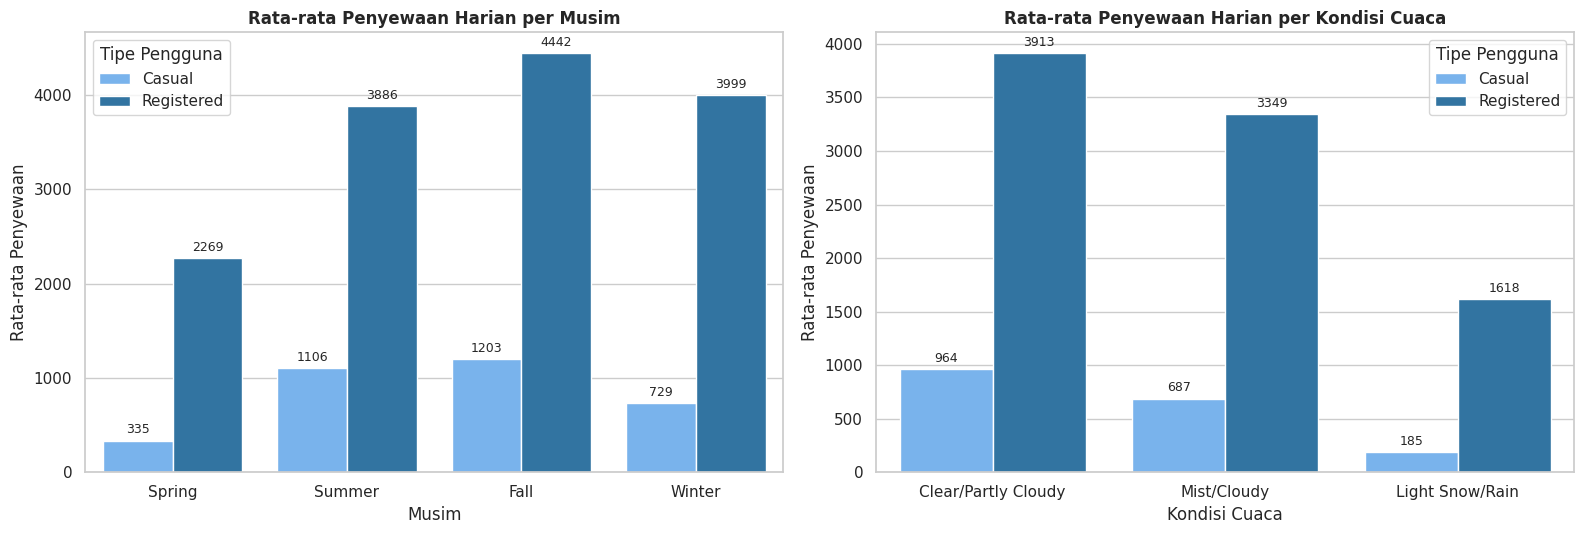

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Grafik 1: Pengaruh Musim (Gunakan 'season_label')
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_melt = day_df.melt(
    id_vars='season_label',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)
sns.barplot(
    data=season_melt,
    x='season_label',
    y='avg_rentals',
    hue='user_type',
    order=season_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan")
axes[0].legend(title="Tipe Pengguna", labels=["Casual", "Registered"])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

# Grafik 2: Pengaruh Kondisi Cuaca (Samakan string dengan weather_map)
weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_melt = day_df.melt(
    id_vars='weather_condition',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)
sns.barplot(
    data=weather_melt,
    x='weather_condition',
    y='avg_rentals',
    hue='user_type',
    order=weather_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan")
axes[1].legend(title="Tipe Pengguna", labels=["Casual", "Registered"])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbandingan pola jam sibuk penyewaan sepeda antara hari kerja dan akhir pekan/hari libur untuk pengguna casual dan registered, guna menentukan waktu promosi dan jadwal ketersediaan unit sepeda?

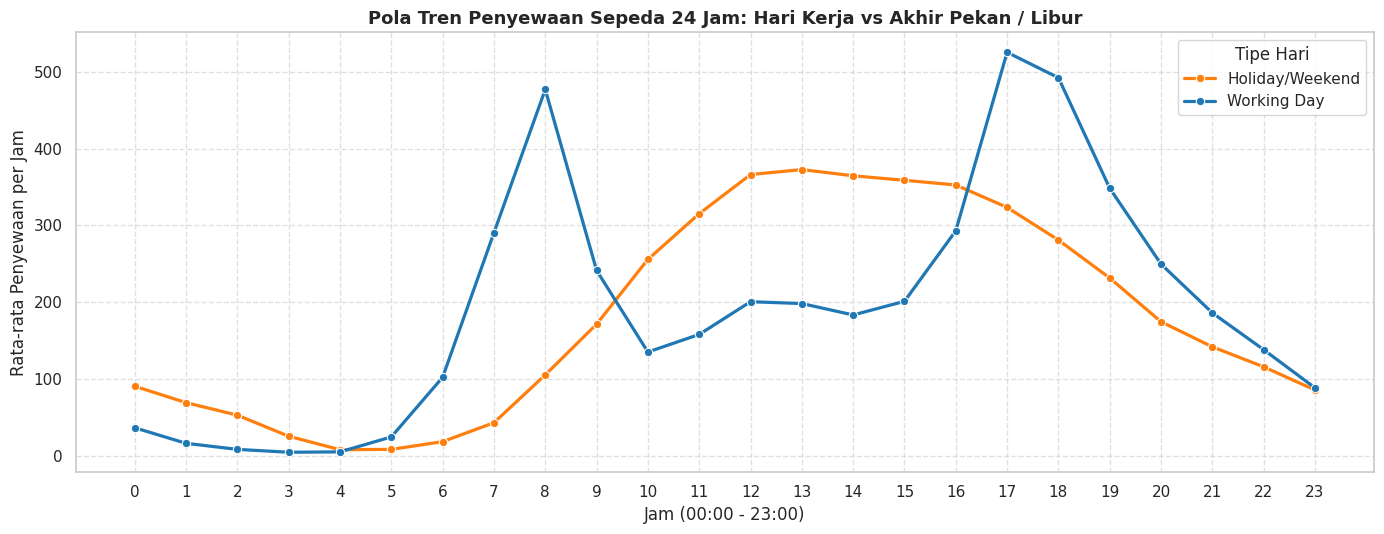

In [7]:
plt.figure(figsize=(14, 5.5))

sns.lineplot(
    data=hour_df,
    x='hr',
    y='cnt',
    hue='workingday_label',
    palette=['#ff7f0e', '#1f77b4'],
    marker='o',
    linewidth=2.3,
    errorbar=None
)

plt.title("Pola Tren Penyewaan Sepeda 24 Jam: Hari Kerja vs Akhir Pekan / Libur", fontsize=13, fontweight='bold')
plt.xlabel("Jam (00:00 - 23:00)")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.xticks(range(0, 24))
plt.legend(title="Tipe Hari")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

1. **Pola Bimodal (Dua Puncak) pada Hari Kerja (*Working Day*):** Pada hari kerja, terjadi lonjakan tajam pada jam berangkat kerja pukul **08:00** (mencapai sekitar **477** penyewaan/jam) dan jam pulang kerja pukul **17:00–18:00** (puncak tertinggi di atas **520** penyewaan/jam). Sebaliknya, aktivitas penyewaan pada siang hari (10:00–15:00) cenderung melandai di kisaran 135–200 penyewaan/jam.
2. **Pola Unimodal (Satu Puncak Panjang) pada Akhir Pekan/Libur (*Holiday/Weekend*):** Pada akhir pekan atau hari libur, lonjakan komuter pagi hari tidak terjadi (pukul 08:00 hanya sekitar **106** penyewaan/jam). Permintaan meningkat bertahap mulai pagi dan memuncak secara stabil pada siang hingga sore hari pukul **12:00–16:00** (berkisar antara **350 hingga 373** penyewaan/jam), yang mencerminkan pola penggunaan untuk aktivitas rekreasi.

## Analisis Lanjutan (Opsional)

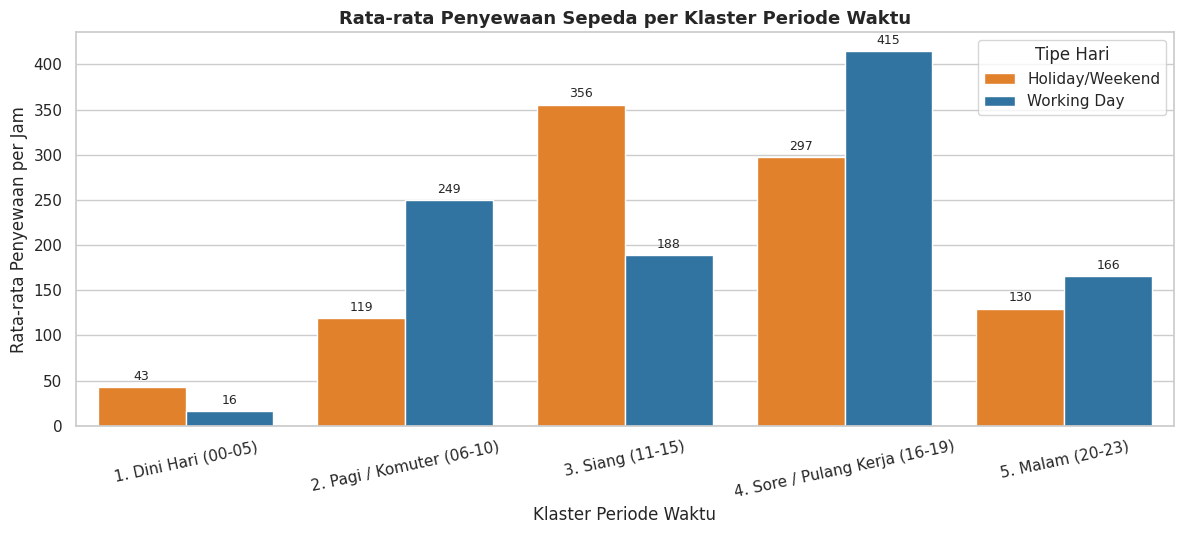

In [8]:
# Teknik Analisis Lanjutan: Manual Grouping / Clustering berdasarkan Periode Waktu Operasional
def categorize_time_period(hr):
    if 0 <= hr <= 5:
        return '1. Dini Hari (00-05)'
    elif 6 <= hr <= 10:
        return '2. Pagi / Komuter (06-10)'
    elif 11 <= hr <= 15:
        return '3. Siang (11-15)'
    elif 16 <= hr <= 19:
        return '4. Sore / Pulang Kerja (16-19)'
    else:
        return '5. Malam (20-23)'

hour_df['time_period'] = hour_df['hr'].apply(categorize_time_period)

# Simpan ulang main_hour_data.csv agar kolom time_period ikut tersimpan
hour_df.to_csv("main_hour_data.csv", index=False)

period_order = [
    '1. Dini Hari (00-05)',
    '2. Pagi / Komuter (06-10)',
    '3. Siang (11-15)',
    '4. Sore / Pulang Kerja (16-19)',
    '5. Malam (20-23)'
]

plt.figure(figsize=(12, 5.5))
ax = sns.barplot(
    data=hour_df,
    x='time_period',
    y='cnt',
    hue='workingday_label',
    order=period_order,
    palette=['#ff7f0e', '#1f77b4'],
    errorbar=None
)
plt.title("Rata-rata Penyewaan Sepeda per Klaster Periode Waktu", fontsize=13, fontweight='bold')
plt.xlabel("Klaster Periode Waktu")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.xticks(rotation=12)
plt.legend(title="Tipe Hari")
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Penjelasan Teknik Analisis Lanjutan (Manual Grouping / Binning)
Untuk mempermudah pengambilan keputusan operasional harian, data penyewaan per jam dikelompokkan (*binning*) ke dalam **5 klaster periode waktu**:
1. **Dini Hari (00:00–05:00):** Periode istirahat/operasional minimum.
2. **Pagi / Komuter (06:00–10:00):** Jam berangkat kerja dan sekolah.
3. **Siang (11:00–15:00):** Jam istirahat siang dan aktivitas rekreasi.
4. **Sore / Pulang Kerja (16:00–19:00):** Jam pulang kantor dan aktivitas sore.
5. **Malam (20:00–23:00):** Periode penurunan aktivitas menuju malam hari.

**Insight Analisis Lanjutan:**
1. **Klaster Puncak Tertinggi (*Prime Time*):** Klaster **4. Sore / Pulang Kerja (16–19)** mencatatkan rata-rata penyewaan tertinggi secara keseluruhan, khususnya pada **Working Day** yang mencapai **415 penyewaan/jam** (dan tetap tinggi di **Holiday/Weekend** sebesar **297 penyewaan/jam**).
2. **Pergeseran Dominasi Pagi vs Siang:** Pada **Working Day**, klaster **2. Pagi / Komuter (06–10)** sangat tinggi (**249 penyewaan/jam**, lebih dari dua kali lipat dibanding akhir pekan yang hanya **119**). Sebaliknya, pada **Holiday/Weekend**, permintaan justru berbalik mendominasi klaster **3. Siang (11–15)** dengan rata-rata **356 penyewaan/jam** (jauh melampaui hari kerja yang hanya **188**).
3. **Waktu Optimal Redistribusi & Perawatan Ringan:** Klaster **1. Dini Hari (00–05)** memiliki tingkat penyewaan paling rendah di kedua tipe hari (**16 penyewaan/jam** pada hari kerja dan **43 penyewaan/jam** pada akhir pekan), menjadikannya jendela waktu paling ideal bagi tim lapangan untuk melakukan *rebalancing* (pemindahan unit sepeda antar-stasiun) dan pengecekan ringan sebelum lonjakan pagi dimulai.

## Conclusion & Recommendation

**Conclusion:**


- **Pertanyaan 1 (Perbandingan Rata-rata Penyewaan Harian Berdasarkan Musim dan Kondisi Cuaca):**
  - **Berdasarkan Musim:** Terdapat perbedaan rata-rata penyewaan harian yang cukup besar antar musim pada kedua kategori pengguna. Pada musim dengan penyewaan tertinggi (*Fall*), pengguna *casual* mencatat rata-rata 1.202,6 penyewaan/hari dan pengguna *registered* sebesar 4.441,7 penyewaan/hari (total 5.644,3 penyewaan/hari). Sebaliknya, pada musim dengan penyewaan terendah (*Spring*), rata-rata pengguna *casual* tercatat sebesar 334,9 penyewaan/hari dan pengguna *registered* sebesar 2.269,2 penyewaan/hari (total 2.604,1 penyewaan/hari). Hal ini menunjukkan bahwa baik pengguna *casual* maupun *registered* sama-sama mengalami peningkatan rata-rata penggunaan hingga sekitar dua hingga tiga kali lipat dari musim *Spring* ke *Fall*.
  - **Berdasarkan Kondisi Cuaca:** Rata-rata penyewaan harian tertinggi tercatat pada kondisi *Clear/Partly Cloudy*, yakni 964,0 penyewaan/hari untuk pengguna *casual* dan 3.912,8 penyewaan/hari untuk pengguna *registered* (total 4.876,8 penyewaan/hari). Pada kondisi *Mist/Cloudy*, rata-rata tercatat sebesar 687,4 (*casual*) dan 3.348,5 (*registered*). Sementara itu, pada kondisi cuaca terburuk dalam data (*Light Snow/Rain*), rata-rata penyewaan berada di titik terendah, yakni 185,5 penyewaan/hari untuk pengguna *casual* dan 1.617,8 penyewaan/hari untuk pengguna *registered* (total 1.803,3 penyewaan/hari).

- **Pertanyaan 2 (Perbedaan Pola Penyewaan per Jam antara Hari Kerja dan Akhir Pekan/Hari Libur):**
  - **Hari Kerja (*Working Day*):** Pola penyewaan membentuk kurva bimodal (dua puncak) yang mencerminkan aktivitas komuter. Puncak pagi terjadi pada pukul 08:00 dengan rata-rata 477,0 penyewaan/jam, sedangkan puncak tertinggi di sore hari terjadi pada pukul 17:00 dengan rata-rata 525,3 penyewaan/jam dan diikuti pukul 18:00 sebesar 492,2 penyewaan/jam. Lonjakan tajam ini didominasi oleh pengguna *registered*, sementara pengguna *casual* memiliki pola yang relatif datar sepanjang hari kerja.
  - **Akhir Pekan/Hari Libur (*Holiday/Weekend*):** Pola penyewaan membentuk satu puncak landai (*unimodal*) yang mencerminkan aktivitas rekreasi, di mana tingkat penyewaan meningkat secara bertahap sejak pagi, mencapai puncaknya di rentang pukul 11:00 hingga 16:00, lalu berangsur menurun di malam hari. Pada periode ini, proporsi penggunaan oleh segmen *casual* meningkat secara signifikan dibandingkan hari kerja.

**Rekomendasi Action Item:**

1. **Optimalisasi Pengaturan Ketersediaan Armada Berbasis Jam Sibuk:** Tim operasional perlu melakukan penyeimbangan ulang (*rebalancing*) ketersediaan unit sepeda sebelum pukul 07:30 dan sebelum pukul 16:30 pada hari kerja (*Working Day*) guna mengantisipasi lonjakan permintaan komuter pada pukul 08:00 (477,0/jam) serta pukul 17:00 dan 18:00 (masing-masing 525,3 dan 492,2/jam). Pada akhir pekan/hari libur, fokus ketersediaan unit perlu dimaksimalkan pada rentang pukul 11:00–16:00 untuk merespons tingginya aktivitas rekreasi pengguna *casual*.
2. **Penjadwalan Perawatan Armada (*Maintenance*) dan Promo Musiman:** Jadwalkan pemeliharaan besar armada sepeda pada musim *Spring* (rata-rata total terendah: 2.604,1 penyewaan/hari) agar seluruh unit siap beroperasi secara maksimal memasuki puncak permintaan pada musim *Summer* dan *Fall*. Selain itu, berikan insentif atau paket promosi *pass* harian khusus pengguna *casual* pada musim *Spring* dan *Winter* untuk mendongkrak tingkat penyewaan di luar musim puncak.